# 第2章：去噪与去市场成分——原实现 vs skfolio

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed, quiet, matrix_stats

SEED = 42
RUN_EXPENSIVE = False
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 对应关系与公平比较
[原实现](Machine_Learning_for_Asset_Managers/ch2_marcenko_pastur_pdf.py)及
[协方差封装](Machine_Learning_for_Asset_Managers/ch2_monte_carlo_experiment.py)
对应 `DenoiseCovariance` / `DetoneCovariance`。
统一样本协方差 `ddof=1`、带宽0.01、同一训练收益。受控对照关闭正定修复，
另行报告默认修复结果；同一算法也可能因优化器、特征分解和病态输入产生差异。

In [ ]:
from Machine_Learning_for_Asset_Managers import ch2_marcenko_pastur_pdf as original_mp
from Machine_Learning_for_Asset_Managers import ch2_monte_carlo_experiment as original_mc
from skfolio.moments import DenoiseCovariance, DetoneCovariance, EmpiricalCovariance
from skfolio.utils.stats import cov_to_corr
cov = X_train.cov().to_numpy()
q = len(X_train) / len(assets)
old_cov, old_seconds = timed('原协方差去噪', lambda: quiet(lambda: original_mc.deNoiseCov(cov, q, .01)))
new_estimator, new_seconds = timed('skfolio去噪（不正定修复）', lambda: DenoiseCovariance(
    covariance_estimator=EmpiricalCovariance(nearest=False), nearest=False).fit(X_train))
new_cov = new_estimator.covariance_
# DenoiseCovariance默认：两层都开启正定修复
default_cov = DenoiseCovariance().fit(X_train).covariance_
comparison = pd.DataFrame({name: matrix_stats(value) for name, value in
                          {'经验协方差': cov, '原去噪': old_cov, 'skfolio不修复': new_cov,
                           'skfolio默认修复': default_cov}.items()}).T.infer_objects()
display(comparison)
print('最大绝对误差：', np.max(np.abs(old_cov-new_cov)))
print('相对Frobenius误差：', np.linalg.norm(old_cov-new_cov)/np.linalg.norm(old_cov))
print('数值接近：', np.allclose(old_cov, new_cov, rtol=1e-5, atol=1e-10))
assert np.isfinite(old_cov).all() and np.isfinite(new_cov).all()
if data.smoke:
    np.testing.assert_allclose(old_cov, new_cov, rtol=1e-5, atol=1e-10)

开始：原协方差去噪


原函数日志共5行，末尾： sse:341.7390423906984
sse:99.9917377622821
sse:99.99173949849023
found errPDFs0.99999
完成：原协方差去噪，耗时 0.14 秒


开始：skfolio去噪（不修复）


完成：skfolio去噪（不修复），耗时 0.09 秒


,最小特征值,最大特征值,条件数,可Cholesky分解
经验协方差,7.217795e-11,0.063522,8.800756e+08,True
原去噪,1.264061e-10,0.060610,4.794897e+08,True
skfolio不修复,1.264061e-10,0.060610,4.794897e+08,True
skfolio默认修复,1.264061e-10,0.060610,4.794897e+08,True


最大绝对误差： 6.544244313122505e-16
相对Frobenius误差： 2.1287618335099931e-13
数值接近： True


开始：MP拟合诊断


原函数日志共5行，末尾： sse:341.7390423906984
sse:99.9917377622821
sse:99.99173949849023
found errPDFs0.99999
完成：MP拟合诊断，耗时 0.03 秒


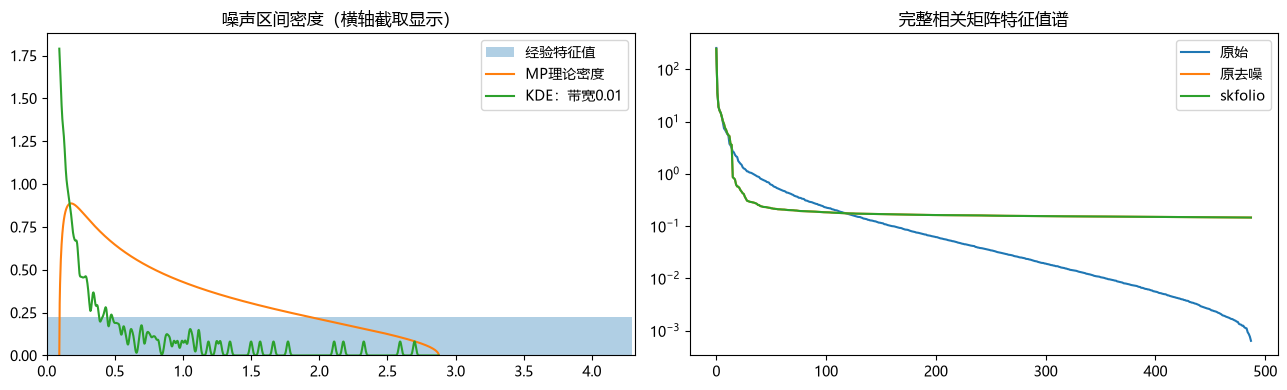

In [3]:
corr = original_mp.cov2corr(cov)
eigenvalues, eigenvectors = original_mp.getPCA(corr)
eigenvalues = np.real_if_close(eigenvalues).astype(float)
eigenvectors = np.real_if_close(eigenvectors).astype(float)
(max_noise, noise_variance), _ = timed('MP拟合诊断', lambda: quiet(
    lambda: original_mp.findMaxEval(np.diag(eigenvalues), q, .01)))
pdf = original_mp.mpPDF(noise_variance, q, 1000)
kde = original_mp.fitKDE(np.diag(eigenvalues), bWidth=.01, x=pdf.index.to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.diag(eigenvalues), bins=60, density=True, alpha=.35, label='经验特征值')
axes[0].plot(pdf.index, pdf.values, label='MP理论密度')
axes[0].plot(kde.index, kde.values, label='KDE：带宽0.01')
axes[0].set_xlim(0, max_noise*1.5)
axes[0].set_title('噪声区间密度（横轴截取显示）')
for name, value in {'原始': cov, '原去噪': old_cov, 'skfolio': new_cov}.items():
    spectrum = np.linalg.eigvalsh(cov_to_corr(value)[0])[::-1]
    axes[1].plot(spectrum, label=name)
axes[1].set_yscale('symlog', linthresh=1e-10)
axes[1].set_title('完整相关矩阵特征值谱')
for axis in axes:
    axis.legend()
plt.tight_layout(); plt.show()

## 2. 去市场成分
仅作为聚类结构分析，不用来代表完整组合风险。去掉一个主成分后矩阵理论上奇异；
`nearest=True` 的微小特征值修复不等于恢复市场风险。

,最小特征值,最大特征值,条件数,可Cholesky分解
原去市场成分,4.748146e-13,76.99591,1.617581e+14,True
skfolio不修复,4.649892e-13,76.99591,1.651080e+14,True
skfolio默认修复,4.649892e-13,76.99591,1.651080e+14,True


去市场成分相关矩阵最大误差： 3.827660410848921e-12


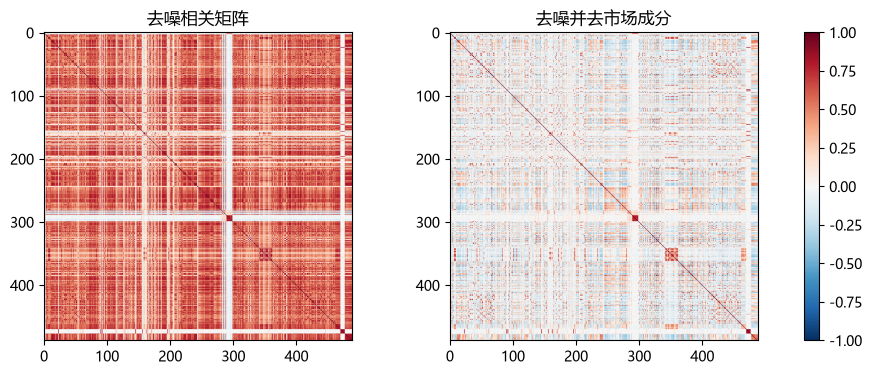

In [ ]:
old_corr = original_mp.cov2corr(old_cov)
values, vectors = original_mp.getPCA(old_corr)
old_detoned = np.real_if_close(original_mp.detoned_corr(old_corr, values, vectors)).astype(float)
# 关闭正定修复：nearest=False
new_detone = DetoneCovariance(covariance_estimator=DenoiseCovariance(
    covariance_estimator=EmpiricalCovariance(nearest=False), nearest=False),
    n_markets=1, nearest=False).fit(X_train)
new_detoned = cov_to_corr(new_detone.covariance_)[0]
repaired = DetoneCovariance(covariance_estimator=DenoiseCovariance()).fit(X_train)
display(pd.DataFrame({'原去市场成分': matrix_stats(old_detoned),
                       'skfolio不修复': matrix_stats(new_detoned),
                       'skfolio默认修复': matrix_stats(cov_to_corr(repaired.covariance_)[0])}).T.infer_objects())
print('去市场成分相关矩阵最大误差：', np.max(np.abs(old_detoned-new_detoned)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, value in zip(axes, ['去噪相关矩阵', '去噪并去市场成分'], [old_corr, old_detoned]):
    image = ax.imshow(value, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_title(title)
fig.colorbar(image, ax=axes.tolist()); plt.show()

## 3. 可选：KDE带宽交叉验证
原 `findOptimalBWidth` 的100候选带宽×留一法会产生大量拟合；设置 `RUN_EXPENSIVE=True`
才执行。skfolio 1.9.11内部带宽固定0.01，没有对应公开带宽参数。
此实验不改变上面的统一带宽比较。

In [5]:
if RUN_EXPENSIVE:
    from Machine_Learning_for_Asset_Managers.ch2_fitKDE_find_best_bandwidth import findOptimalBWidth
    bandwidth_result, _ = timed('原KDE带宽搜索', lambda: findOptimalBWidth(np.diag(eigenvalues)))
    display(bandwidth_result)
else:
    print('带宽搜索扩展未执行；主去噪对照已使用带宽0.01。')

带宽搜索扩展未执行；主去噪对照已使用带宽0.01。


## 结论阅读
矩阵误差衡量实现一致性，条件数衡量数值病态程度，两者不是样本外收益改善的证明。
收益效果在第7章单独比较；去市场成分和去噪的目标不同。